# Feature groups and ablations

Compare archived matched-cohort results with an exploratory correlation diagnostic.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

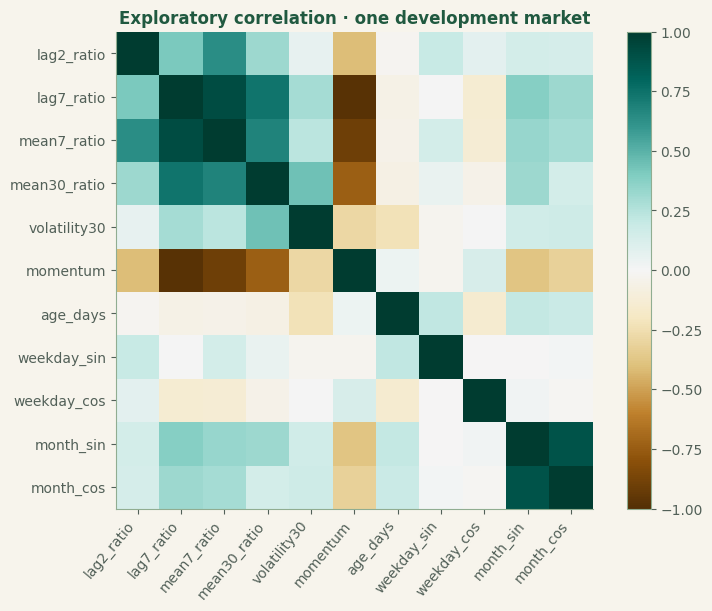

In [2]:
from Code.daily.forecast import features, FEATURES
from Code.daily.policy import IST

h = development_market()
vectors = [features(h, day, day.tz_localize(IST) + pd.Timedelta(hours=8))[0] for day in h.date.tail(90)]
frame = pd.DataFrame([v for v in vectors if v is not None], columns=FEATURES)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
image = ax.imshow(frame.corr(), vmin=-1, vmax=1, cmap="BrBG")
ax.set(xticks=range(len(FEATURES)), yticks=range(len(FEATURES)), yticklabels=FEATURES,
       title="Exploratory correlation · one development market")
ax.set_xticklabels(FEATURES, rotation=50, ha="right")
fig.colorbar(image, ax=ax)
plt.show()

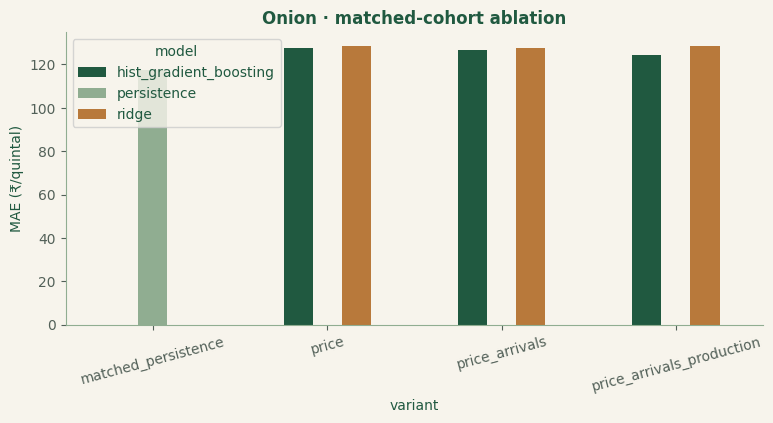

,variant,model,rows,mae,skill_pct
0,matched_persistence,persistence,346,117.54,0.00
1,price,ridge,346,128.46,-9.29
2,price,hist_gradient_boosting,346,127.64,-8.59
3,price_arrivals,ridge,346,127.61,-8.57
4,price_arrivals,hist_gradient_boosting,346,126.54,-7.66
5,price_arrivals_production,ridge,346,128.32,-9.17
6,price_arrivals_production,hist_gradient_boosting,346,124.34,-5.78


interactive(children=(Dropdown(description='Crop', options=('Onion', 'Potato', 'Wheat'), value='Onion'), Butto…

Matched complete-case cohort for price, price+arrivals, price+arrivals+production; all targets before 2019.
Excluded: original availability vintages missing; no guessed historical publication timestamps.
Historical lag assumptions are not verified original publication vintages; current daily arrivals are absent.


In [3]:
study = INTEL / "phase3/factors_v1"
table = pd.read_csv(study / "metrics.csv")
def ablate(crop):
    selected = table[table.crop == crop]
    pivot = selected.pivot(index="variant", columns="model", values="mae")
    pivot.plot.bar(title=f"{crop} · matched-cohort ablation", ylabel="MAE (₹/quintal)", rot=15)
    plt.show()
    display(selected[["variant", "model", "rows", "mae", "skill_pct"]].round(2))
controls(ablate, crop=sorted(table.crop.unique()))
protocol = read_json(study / "protocol.json")
print(protocol["comparison"])
print(protocol["weather"])
print(protocol["reason"])

**Takeaway** · Saved validation and promotion rules determine what was used. Exploratory correlation describes feature redundancy.

**Next** · See how the candidate models produce predictions in Notebook 07.